In [1]:
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
x = np.array([[0.83380926, 0.2549161 ],
 [0.19395792, 0.95496789],
 [0.15375027, 0.67002758],
 [0.23430613, 0.08963071],
 [0.79522865, 0.16085132],
 [0.23673546, 0.41745655],
 [0.38030063, 0.19982149],
 [0.19557524, 0.7424307 ],
 [0.18427504, 0.51594828],
 [0.00261157, 0.91675874],
 [0.6036336, 0.34299902],
 [0.95759736, 0.08772005],
 [0.87372681, 0.20066907],
 [0.82801634, 0.33252956],
 [0.50959832, 0.35823084],
 [0.72969295, 0.7011594 ],
 [0.02517891, 0.47562924],
 [0.05209245, 0.92520508],
 [0.39854072, 0.9499343 ],
 [0.2933663, 0.41928618]])

y = np.array([0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1])
cdict = {0: 'red', 1: 'green'}

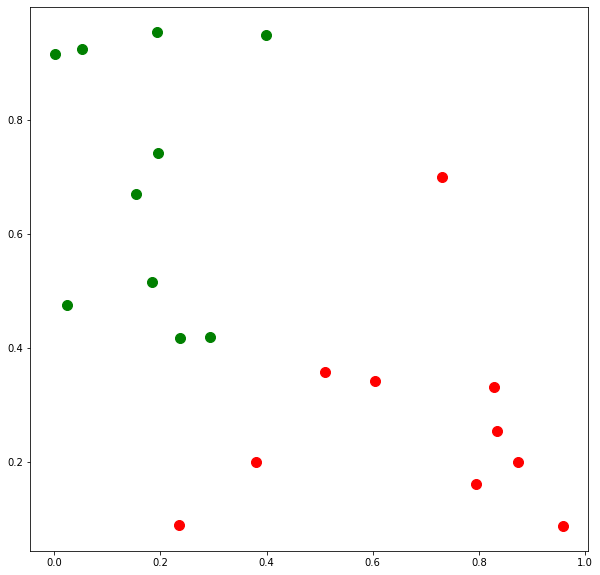

In [3]:
_, ax = plt.subplots(figsize=(10,10))
 
for g in np.unique(y):
    ix = np.where(y == g)
    ax.scatter(x[ix, 0], x[ix, 1], c = cdict[g], label = g, s = 100)

plt.show()
 

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.3,random_state=109) 

In [7]:
from sklearn import svm

#Create a svm Classifier
clf = svm.SVC(kernel='linear') # Linear Kernel

#Train the model using the training sets
clf.fit(X_train, y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

In [8]:
#Import scikit-learn metrics module for accuracy calculation
from sklearn import metrics

# Model Accuracy: how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 1.0


In [9]:
x_second = np.array([[0.83380926, 0.2549161 ],
 [0.19395792, 0.95496789],
 [0.15375027, 0.67002758],
 [0.23430613, 0.08963071],
 [0.79522865, 0.16085132],
 [0.23673546, 0.41745655],
 [0.38030063, 0.19982149],
 [0.19557524, 0.7424307 ],
 [0.18427504, 0.51594828],
 [0.00261157, 0.91675874],
 [0.6036336, 0.34299902],
 [0.95759736, 0.08772005],
 [0.87372681, 0.20066907],
 [0.82801634, 0.33252956],
 [0.50959832, 0.35823084],
 [0.72969295, 0.7011594 ],
 [0.02517891, 0.47562924],
 [0.05209245, 0.92520508],
 [0.39854072, 0.9499343 ],
 [0.2933663, 0.41928618]])

y_second = np.array([0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1])
cdict = {0: 'red', 1: 'green'}

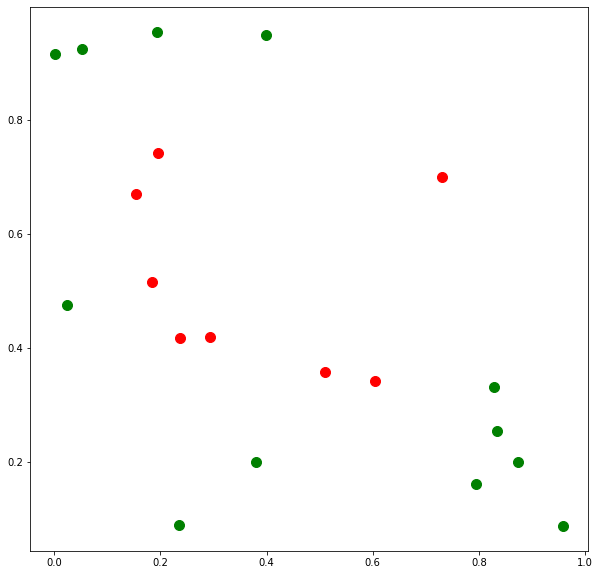

In [10]:
y_second = np.array([1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0])

_, ax = plt.subplots(figsize=(10,10))
 
for g in np.unique(y_second):
    ix = np.where(y_second == g)
    ax.scatter(x_second[ix, 0], x_second[ix, 1], c = cdict[g], label = g, s = 100)

plt.show()

In [11]:
X_train, X_test, y_train, y_test = train_test_split(x_second, y_second, test_size=0.3,random_state=109)
clf = svm.SVC(kernel='linear') # Linear Kernel
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.5


In [12]:
clf = svm.SVC(kernel='poly') # Linear Kernel
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))
clf.get_params()

Accuracy: 0.8333333333333334


{'C': 1.0,
 'break_ties': False,
 'cache_size': 200,
 'class_weight': None,
 'coef0': 0.0,
 'decision_function_shape': 'ovr',
 'degree': 3,
 'gamma': 'scale',
 'kernel': 'poly',
 'max_iter': -1,
 'probability': False,
 'random_state': None,
 'shrinking': True,
 'tol': 0.001,
 'verbose': False}

In [13]:
from sklearn.model_selection import GridSearchCV

# Set the parameters by cross-validation
tuned_parameters = [{'kernel': ['poly', 'rbf', 'sigmoid'],
                     'degree': range(3, 5),
                     'coef0': np.arange(0, 1, 0.1)}]

clf = GridSearchCV(
        svm.SVC(), tuned_parameters
    )

clf.fit(X_train, y_train)

print("Best parameters set found on development set:")
print()
print(clf.best_params_)

print("Accuracy:",metrics.accuracy_score(y_test, clf.predict(X_test)))

Best parameters set found on development set:

{'coef0': 0.0, 'degree': 4, 'kernel': 'poly'}
Accuracy: 0.8333333333333334


In [ ]:
# Z = clf.decision_function(x_second)